The following is a netbook to clean and produce CSVs to utilize negbench to review negation query accuracies on the cheXpert dataset.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
# for file access across drive

In [ ]:
# traditional loading process below
# df = pd.read_csv('train.csv')

# drive setup
drive.mount('/content/drive')

# referencing file from drive
file_path = '/content/drive/MyDrive/intro-data-science/train.csv' # used by adamya

gokul_file_path = '/content/drive/MyDrive/Research/train.csv' # used by gokul

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


The following is a brief check for the dataset.

In [ ]:
# verify if file path is valid
df = pd.read_csv(gokul_file_path)
print(df.head())

                                                Path     Sex  Age  \
0  CheXpert-v1.0-small/train/patient00001/study1/...  Female   68   
1  CheXpert-v1.0-small/train/patient00002/study2/...  Female   87   
2  CheXpert-v1.0-small/train/patient00002/study1/...  Female   83   
3  CheXpert-v1.0-small/train/patient00002/study1/...  Female   83   
4  CheXpert-v1.0-small/train/patient00003/study1/...    Male   41   

  Frontal/Lateral AP/PA  No Finding  Enlarged Cardiomediastinum  Cardiomegaly  \
0         Frontal    AP         1.0                         NaN           NaN   
1         Frontal    AP         NaN                         NaN          -1.0   
2         Frontal    AP         NaN                         NaN           NaN   
3         Lateral   NaN         NaN                         NaN           NaN   
4         Frontal    AP         NaN                         NaN           NaN   

   Lung Opacity  Lung Lesion  Edema  Consolidation  Pneumonia  Atelectasis  \
0           NaN     


--- Distribution for class 'Enlarged Cardiomediastinum' ---
Enlarged Cardiomediastinum
 NaN    178575
 0.0     21638
-1.0     12403
 1.0     10798
Name: count, dtype: int64
Unique possibilities in 'Enlarged Cardiomediastinum' (3 options): [nan  0.  1. -1.]
Column 'Enlarged Cardiomediastinum': 79.93% of the entries are NaN.
Column 'Enlarged Cardiomediastinum': 20.07% of the entries are non-NaN.


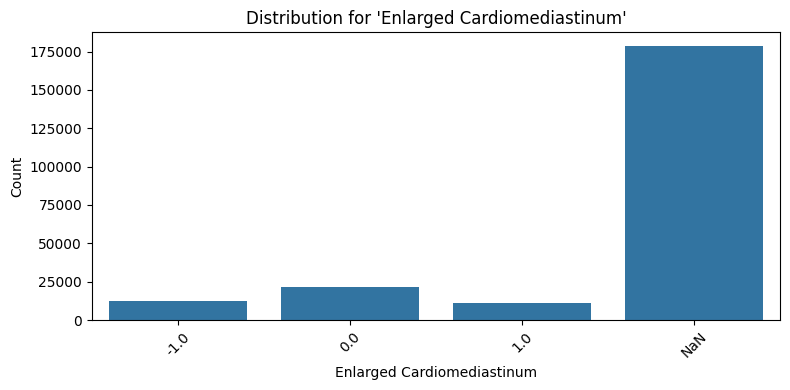


--- Distribution for class 'Cardiomegaly' ---
Cardiomegaly
 NaN    177211
 1.0     27000
 0.0     11116
-1.0      8087
Name: count, dtype: int64
Unique possibilities in 'Cardiomegaly' (3 options): [nan -1.  0.  1.]
Column 'Cardiomegaly': 79.32% of the entries are NaN.
Column 'Cardiomegaly': 20.68% of the entries are non-NaN.


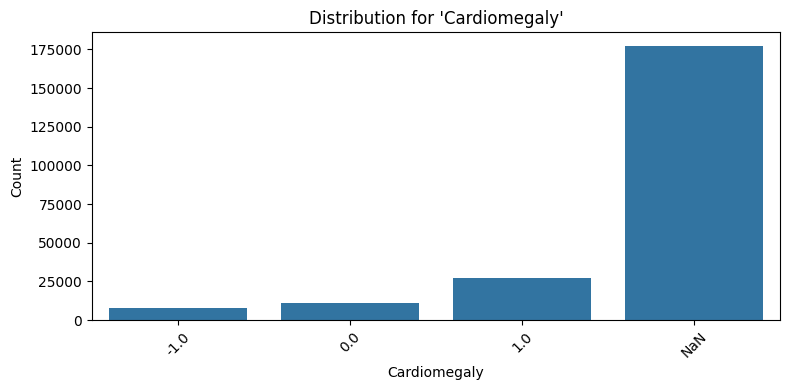


--- Distribution for class 'Lung Opacity' ---
Lung Opacity
 NaN    105636
 1.0    105581
 0.0      6599
-1.0      5598
Name: count, dtype: int64
Unique possibilities in 'Lung Opacity' (3 options): [nan  1.  0. -1.]
Column 'Lung Opacity': 47.28% of the entries are NaN.
Column 'Lung Opacity': 52.72% of the entries are non-NaN.


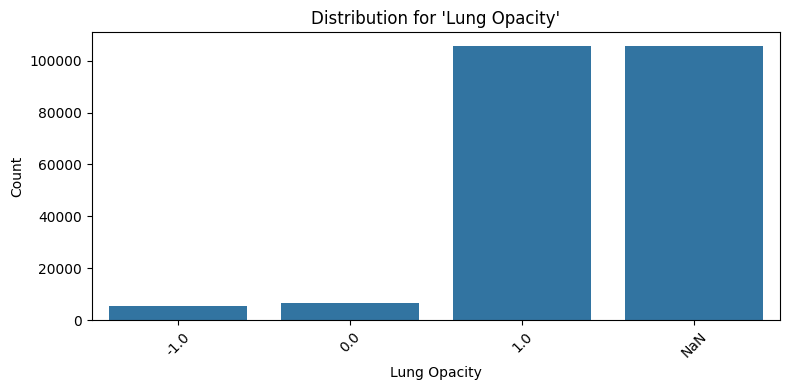


--- Distribution for class 'Lung Lesion' ---
Lung Lesion
 NaN    211470
 1.0      9186
-1.0      1488
 0.0      1270
Name: count, dtype: int64
Unique possibilities in 'Lung Lesion' (3 options): [nan  1. -1.  0.]
Column 'Lung Lesion': 94.65% of the entries are NaN.
Column 'Lung Lesion': 5.35% of the entries are non-NaN.


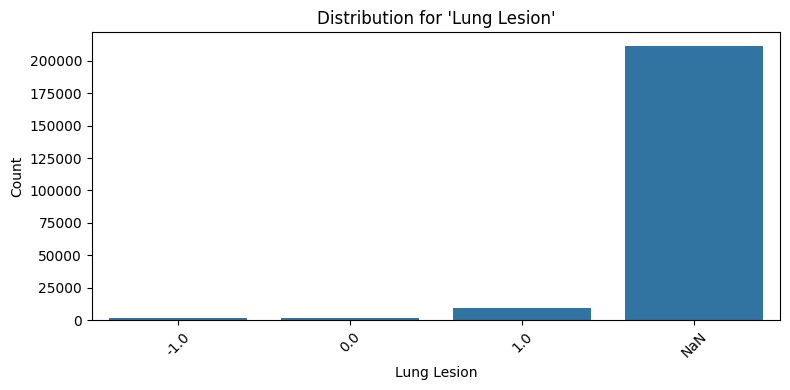


--- Distribution for class 'Edema' ---
Edema
 NaN    137458
 1.0     52246
 0.0     20726
-1.0     12984
Name: count, dtype: int64
Unique possibilities in 'Edema' (3 options): [nan -1.  1.  0.]
Column 'Edema': 61.53% of the entries are NaN.
Column 'Edema': 38.47% of the entries are non-NaN.


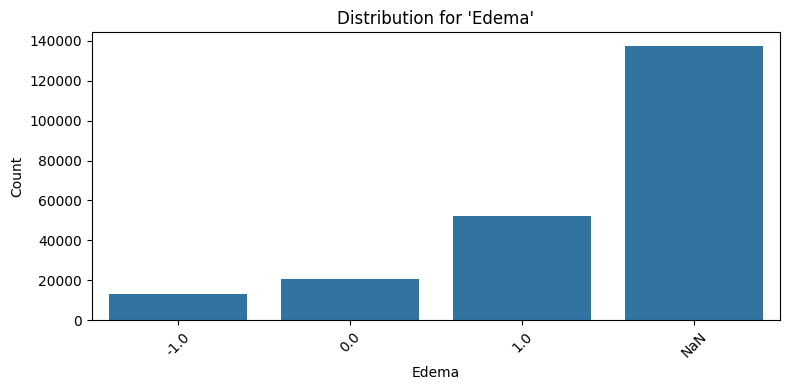


--- Distribution for class 'Consolidation' ---
Consolidation
 NaN    152792
 0.0     28097
-1.0     27742
 1.0     14783
Name: count, dtype: int64
Unique possibilities in 'Consolidation' (3 options): [nan -1.  0.  1.]
Column 'Consolidation': 68.39% of the entries are NaN.
Column 'Consolidation': 31.61% of the entries are non-NaN.


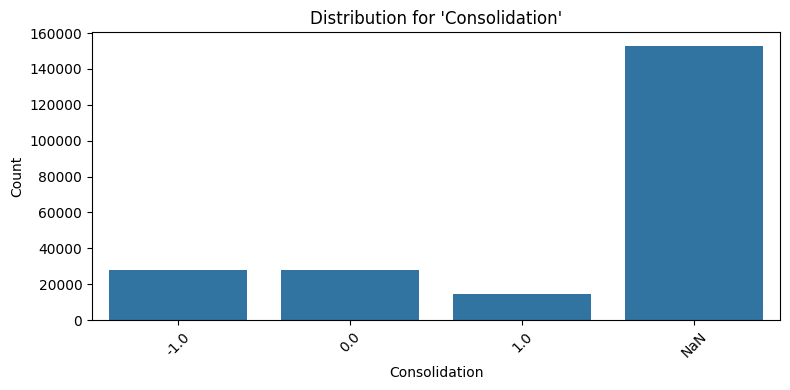


--- Distribution for class 'Pneumonia' ---
Pneumonia
 NaN    195806
-1.0     18770
 1.0      6039
 0.0      2799
Name: count, dtype: int64
Unique possibilities in 'Pneumonia' (3 options): [nan  0. -1.  1.]
Column 'Pneumonia': 87.64% of the entries are NaN.
Column 'Pneumonia': 12.36% of the entries are non-NaN.


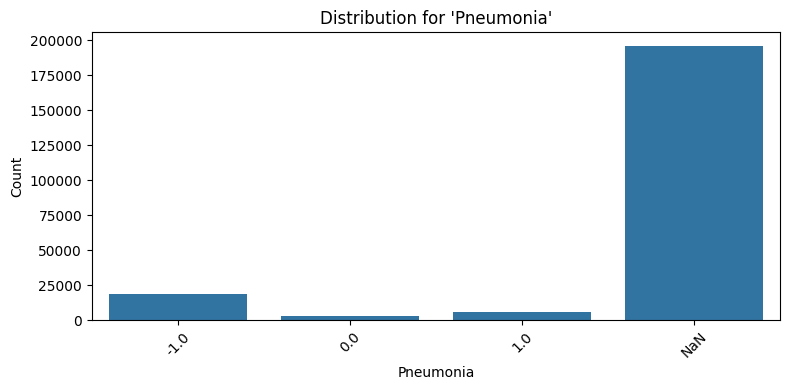


--- Distribution for class 'Atelectasis' ---
Atelectasis
 NaN    154971
-1.0     33739
 1.0     33376
 0.0      1328
Name: count, dtype: int64
Unique possibilities in 'Atelectasis' (3 options): [nan -1.  1.  0.]
Column 'Atelectasis': 69.36% of the entries are NaN.
Column 'Atelectasis': 30.64% of the entries are non-NaN.


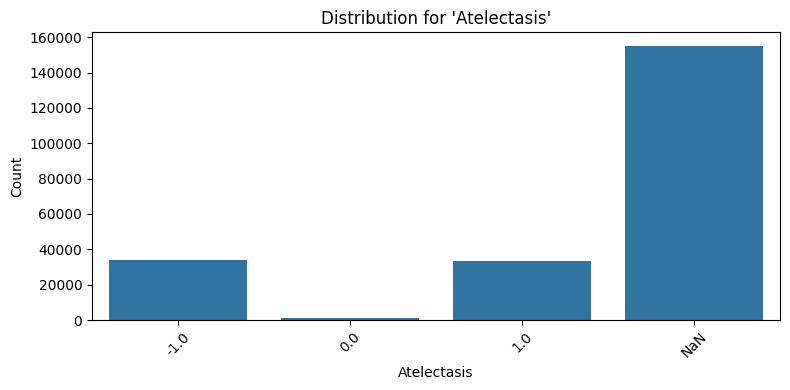


--- Distribution for class 'Pneumothorax' ---
Pneumothorax
 NaN    144480
 0.0     56341
 1.0     19448
-1.0      3145
Name: count, dtype: int64
Unique possibilities in 'Pneumothorax' (3 options): [ 0. nan  1. -1.]
Column 'Pneumothorax': 64.67% of the entries are NaN.
Column 'Pneumothorax': 35.33% of the entries are non-NaN.


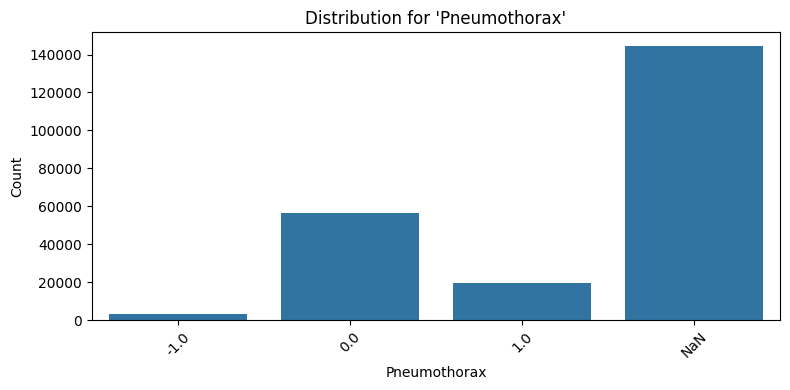


--- Distribution for class 'Pleural Effusion' ---
Pleural Effusion
 NaN    90203
 1.0    86187
 0.0    35396
-1.0    11628
Name: count, dtype: int64
Unique possibilities in 'Pleural Effusion' (3 options): [nan -1.  0.  1.]
Column 'Pleural Effusion': 40.37% of the entries are NaN.
Column 'Pleural Effusion': 59.63% of the entries are non-NaN.


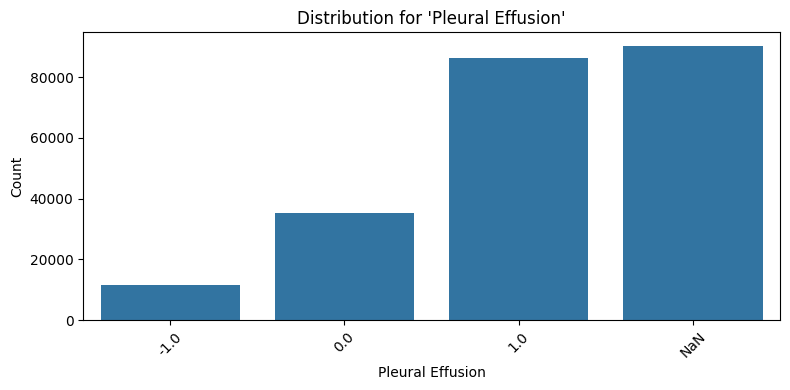


--- Distribution for class 'Pleural Other' ---
Pleural Other
 NaN    216922
 1.0      3523
-1.0      2653
 0.0       316
Name: count, dtype: int64
Unique possibilities in 'Pleural Other' (3 options): [nan  1. -1.  0.]
Column 'Pleural Other': 97.09% of the entries are NaN.
Column 'Pleural Other': 2.91% of the entries are non-NaN.


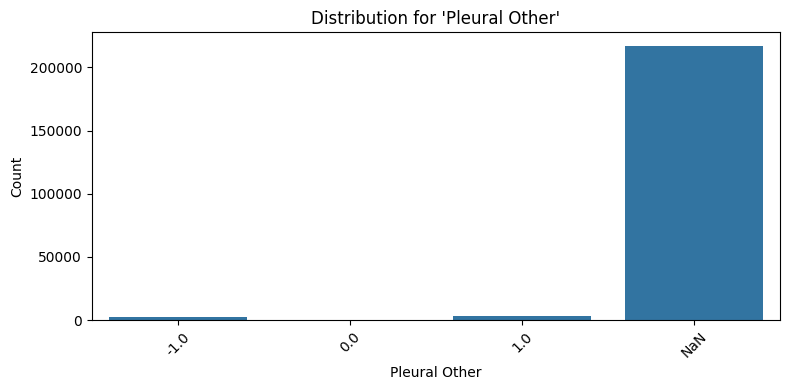


--- Distribution for class 'Fracture' ---
Fracture
 NaN    211220
 1.0      9040
 0.0      2512
-1.0       642
Name: count, dtype: int64
Unique possibilities in 'Fracture' (3 options): [nan  1.  0. -1.]
Column 'Fracture': 94.54% of the entries are NaN.
Column 'Fracture': 5.46% of the entries are non-NaN.


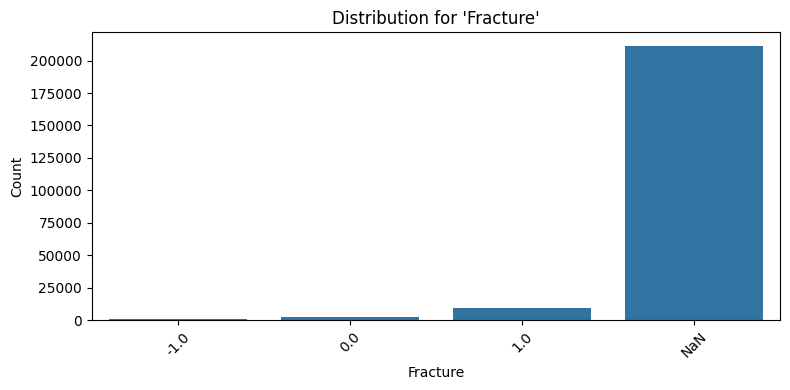


--- Distribution for class 'Support Devices' ---
Support Devices
 1.0    116001
 NaN    100197
 0.0      6137
-1.0      1079
Name: count, dtype: int64
Unique possibilities in 'Support Devices' (3 options): [ 1. nan  0. -1.]
Column 'Support Devices': 44.85% of the entries are NaN.
Column 'Support Devices': 55.15% of the entries are non-NaN.


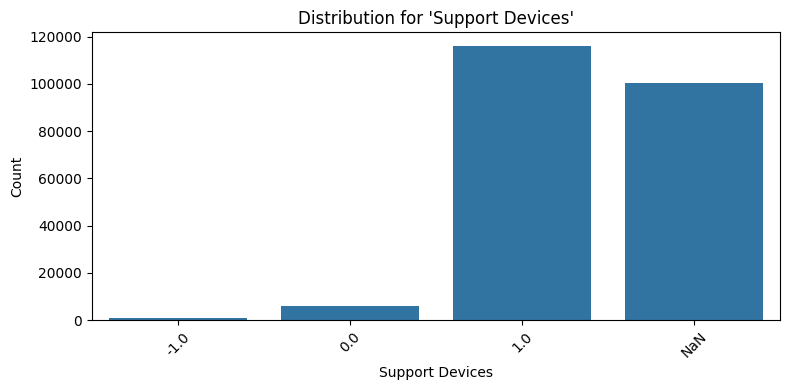

In [ ]:
# EDA Step 1:
# To view the distribution of classes and their labels
# 'Basic' data like the image path, image type (frontal/lateral) are discluded and we focus on condition classes instead

non_label_cols = ['Path', 'Follow-up', 'No Finding', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA']
label_cols = [col for col in df.columns if col not in non_label_cols]

# go through all relevant classes
for col in label_cols:
    print(f"\n--- Distribution for class '{col}' ---")

    # count each unique value (including NaN too)
    counts = df[col].value_counts(dropna=False)
    print(counts)

    # print unique probabilties and their counts
    unique_values = df[col].unique()
    n_options = df[col].nunique(dropna=True)
    print(f"Unique possibilities in '{col}' ({n_options} options): {unique_values}")

    n_nan = df[col].isna().sum()
    # get total num of column entries
    total_entries = len(df[col])
    # find nan percent
    nan_percentage = (n_nan / total_entries) * 100
    non_nan_percentage = 100 - nan_percentage
    print(f"Column '{col}': {nan_percentage:.2f}% of the entries are NaN.")
    print(f"Column '{col}': {non_nan_percentage:.2f}% of the entries are non-NaN.")

    # fill empty values with string 'NaN'
    col_data = df[col].fillna('NaN')

    # produce sorted list of unique vals
    unique_sorted = sorted(col_data.unique(), key=lambda x: str(x))

    # create bar plot for distributions
    plt.figure(figsize=(8, 4))
    sns.countplot(x=col_data, order=unique_sorted)
    plt.title(f"Distribution for '{col}'")
    plt.xlabel(col)
    plt.ylabel("Count")

    # rotate bottom labels slightly
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

(Lung Opacity, Pleural Effusion, Support Devices)    5835
(Lung Opacity, Pneumothorax, Support Devices)        3395
(Edema, Lung Opacity, Support Devices)               2542
(Edema, Pleural Effusion, Support Devices)           1997
(Atelectasis, Consolidation, Lung Opacity)           1842
(Pleural Effusion, Pneumothorax, Support Devices)    1761
(Edema, Lung Opacity, Pleural Effusion)              1749
(Atelectasis, Pleural Effusion, Support Devices)     1488
(Atelectasis, Pneumothorax, Support Devices)         1481
(Cardiomegaly, Edema, Support Devices)               1426
Name: count, dtype: int64


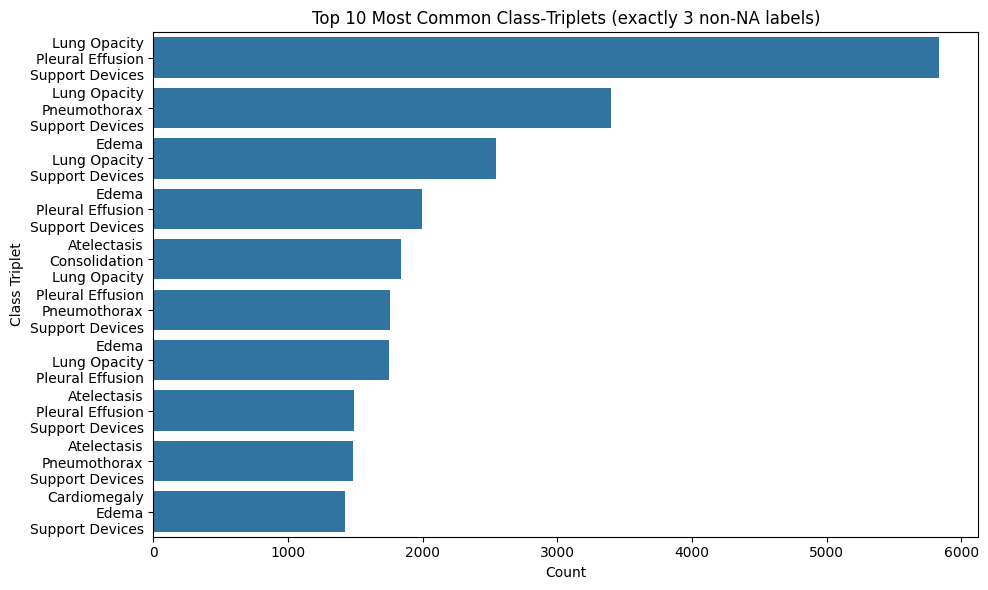

In [ ]:
# EDA Step 2:
# To view the distribution of triplet class combinations
# 'Basic' data like the image path, image type (frontal/lateral) are discluded and we focus on condition classes instead

# NOT: This includes NAN and -1 labels!

non_label_cols = ['Path', 'Follow‑up', 'No Finding', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA']
label_cols = [c for c in df.columns if c not in non_label_cols]

# filter for rows w/ three non-NaN labels
mask_three = (df[label_cols].count(axis=1) == 3)
df_three = df[mask_three]

# for each row make sorted tuple of class names which are non null
combos = df_three[label_cols].apply(
    lambda row: tuple(sorted(row.index[row.notna()])),
    axis=1
)

# get counts
combo_counts = combos.value_counts()

# get top 10 combos
top_n = 10
top_combos = combo_counts.head(top_n)

print(top_combos)

# visualize
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_combos.values,
    y=['\n'.join(c) for c in top_combos.index],  # join the 3 class‐names with newlines
    orient='h'
)
plt.title(f"Top {top_n} Most Common Class‑Triplets (exactly 3 non‑NA labels)")
plt.xlabel("Count")
plt.ylabel("Class Triplet")
plt.tight_layout()
plt.show()

(Edema, Lung Opacity, Pleural Effusion)                         9241
(Lung Opacity, Pleural Effusion, Pneumothorax)                  7618
(Atelectasis, Lung Opacity, Pleural Effusion)                   2413
(Atelectasis, Edema, Pleural Effusion)                          2346
(Cardiomegaly, Edema, Pleural Effusion)                         2098
(Cardiomegaly, Lung Opacity, Pleural Effusion)                  2085
(Cardiomegaly, Edema, Lung Opacity)                             2040
(Enlarged Cardiomediastinum, Lung Opacity, Pleural Effusion)    1676
(Consolidation, Edema, Pleural Effusion)                        1448
(Consolidation, Pleural Effusion, Pneumothorax)                 1426
Name: count, dtype: int64


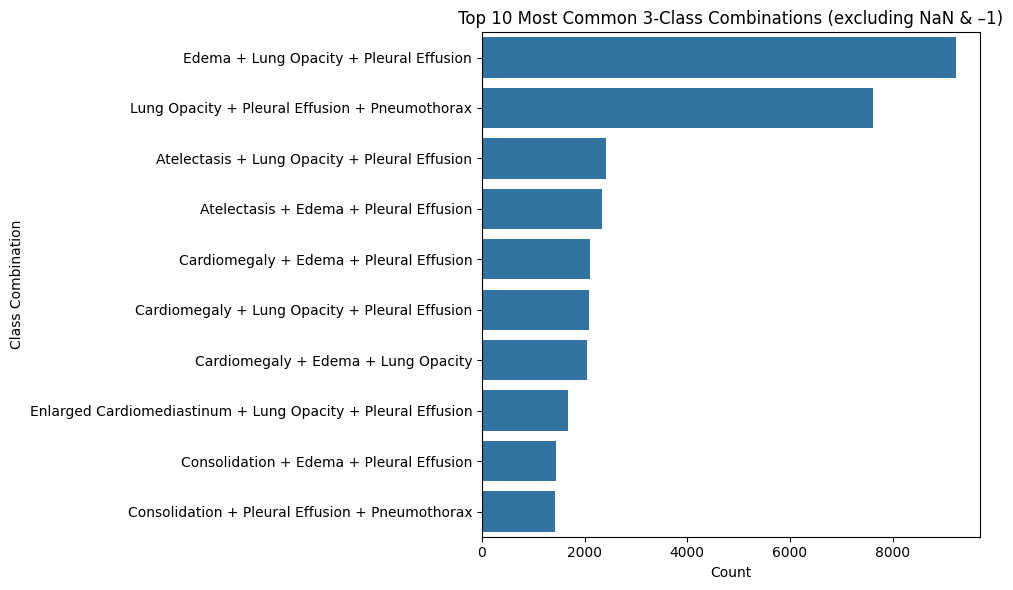

In [ ]:
# EDA Step 3:
# To view the distribution of triplet class combinations
# 'Basic' data like the image path, image type (frontal/lateral) are discluded and we focus on condition classes instead

# NOT: This EXCLUDES NAN and -1 labels!

non_label = ['Path', 'Follow‑up', 'No Finding', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'Support Devices']
label_cols = [c for c in df.columns if c not in non_label]

# include only positive and negative labels
valid_mask = df[label_cols].notna() & (df[label_cols] != -1)

# keep rows with 3 valid labels
mask_three = valid_mask.sum(axis=1) == 3
df_three = df[mask_three]

# for each row get class‐names triplet
combos = valid_mask[mask_three].apply(
    lambda row: tuple(sorted(row.index[row])),
    axis=1
)

# count frequencies
combo_counts = combos.value_counts()

# get top 10 combos
top_n = 10
top_combos = combo_counts.head(top_n)

print(top_combos)

# visualize
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_combos.values,
    y=[' + '.join(c) for c in top_combos.index],  # join class names with '+' for readability
    orient='h'
)
plt.title(f"Top {top_n} Most Common 3‑Class Combinations (excluding NaN & –1)")
plt.xlabel("Count")
plt.ylabel("Class Combination")
plt.tight_layout()
plt.show()

<ipython-input-10-abf975184a7c>:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
<ipython-input-10-abf975184a7c>:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
<ipython-input-10-abf975184a7c>:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
<ipython-input-10-abf975184a7c>:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
<ipython-input-10-abf975184a7c>:54: UserWarning: set_ticklabels() should

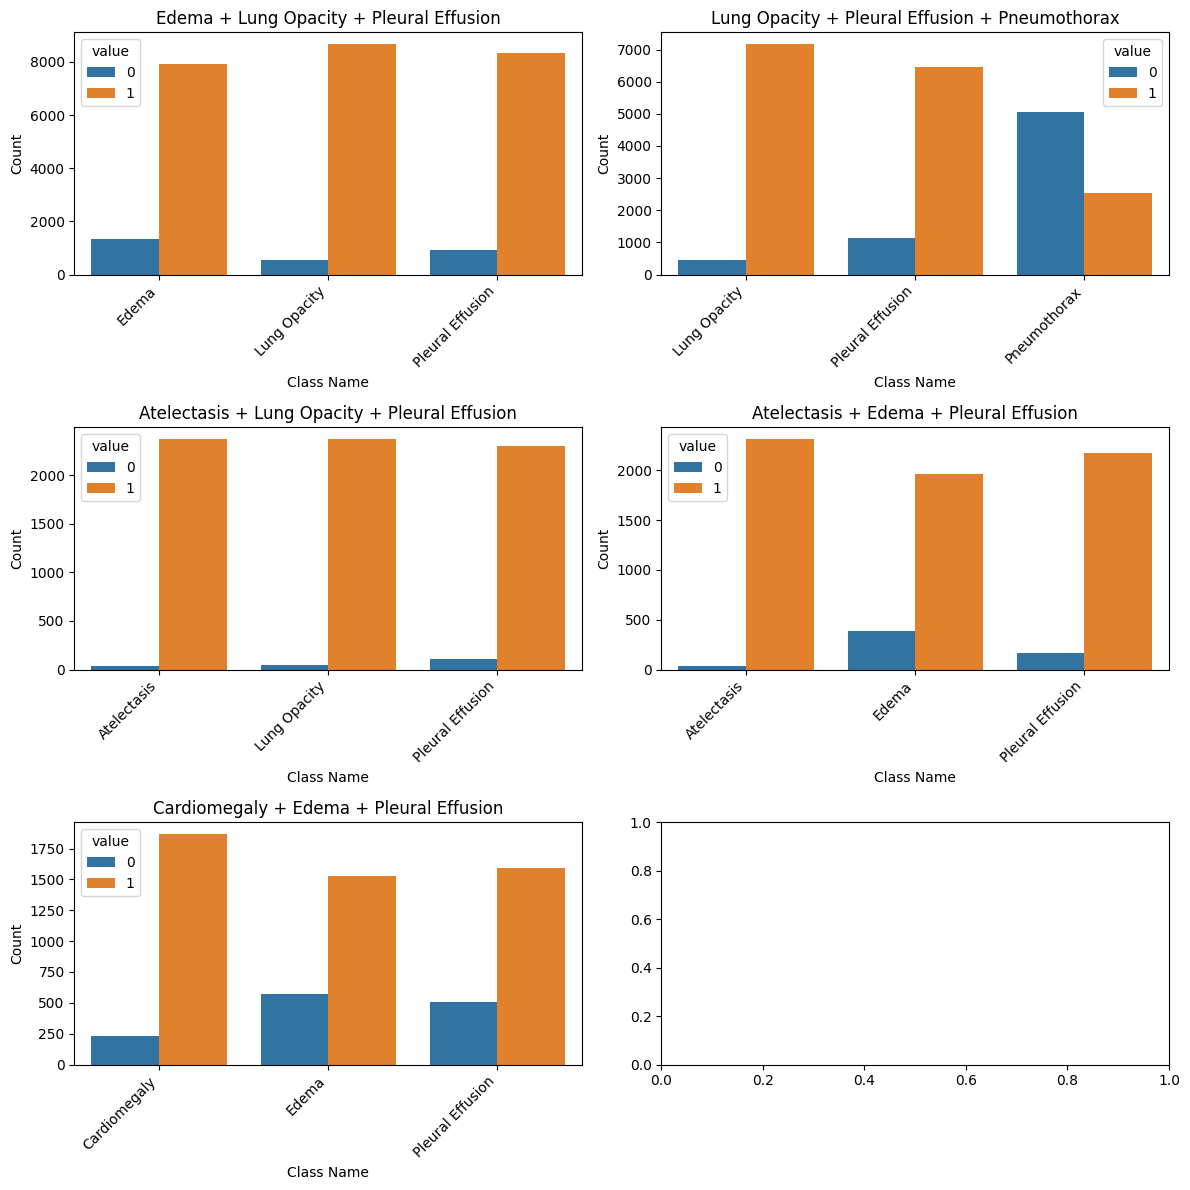

In [ ]:
# EDA Step 4:
# To view the distribution of labels across triplet class combinations
# 'Basic' data like the image path, image type (frontal/lateral) are discluded and we focus on condition classes instead

# NOT: This includes NAN and -1 labels!

# clean labels
non_label = ['Path', 'Follow‑up', 'No Finding', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'Support Devices']
label_cols = [c for c in df.columns if c not in non_label]

# get valid labels
valid_mask = df[label_cols].notna() & (df[label_cols] != -1)

# keep only rows w/ valid labels
mask_three = valid_mask.sum(axis=1) == 3
df_three = df[mask_three].copy()

# get sorted tuple of class names
combos = valid_mask[mask_three].apply(lambda row: tuple(sorted(row.index[row])), axis=1)

# count frequencies for top 5
top5 = combos.value_counts().head(5).index

# setup df for counts
records = []
for triplet in top5:
    sel_idx = combos[combos == triplet].index
    sub = df_three.loc[sel_idx, list(triplet)]
    for cls in triplet:
        vc = sub[cls].value_counts().to_dict()
        records.append({'triplet': ' + '.join(triplet), 'class': cls, 'value': 0, 'count': vc.get(0, 0)})
        records.append({'triplet': ' + '.join(triplet), 'class': cls, 'value': 1, 'count': vc.get(1, 0)})
df_counts = pd.DataFrame(records)

# visualize
n = len(top5)
cols = 2
rows = (n + 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows), sharey=False)

for ax, triplet in zip(axes.flat, top5):
    grp = df_counts[df_counts['triplet'] == ' + '.join(triplet)]
    sns.barplot(
        ax=ax,
        data=grp,
        x='class',
        y='count',
        hue='value',
        dodge=True
    )
    ax.set_title(' + '.join(triplet))
    ax.set_xlabel("Class Name")
    ax.set_ylabel("Count")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

At this point the best candidates are:
1. Lung Opacity, Pleural Effusion, Pneumothorax - 7618 rows
2. Edema, Lung Opacity, Pleural Effusion - 9241 rows        

In [ ]:
# Data Cleaning Step 1:
# Naive approach to 1. get ~3000 rows 2. have ~20%+ of each label
# 'Basic' data like the image path, image type (frontal/lateral) are discluded and we focus on condition classes instead

# dependencies
from sklearn.model_selection import train_test_split
import numpy as np

# normal cleaning
non_label = ['Path', 'Follow‑up', 'No Finding', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'Support Devices']
label_cols = [c for c in df.columns if c not in non_label]

# only positive and negative, no NAN's and -1
valid_mask = df[label_cols].notna() & (df[label_cols] != -1)

# keep rows w/ exactly 3 valid labels
mask_three = valid_mask.sum(axis=1) == 3
df_three = df[mask_three].copy()

# triplet identificiation
triplets = valid_mask[mask_three].apply(
    lambda row: tuple(sorted(row.index[row])), axis=1
)

# find triplet combos w/ atleast 5000 rows
triplet_counts = triplets.value_counts()
big_triplets = triplet_counts[triplet_counts >= 5000].index.tolist()

samples = {}
for triplet in big_triplets:
    sub_idx = triplets[triplets == triplet].index
    sub_df  = df_three.loc[sub_idx]

    # 20%+ check
    ok = True
    for cls in triplet:
        freqs = sub_df[cls].value_counts(normalize=True)
        if freqs.get(0, 0) < 0.15 or freqs.get(1, 0) < 0.15:
            ok = False
            break
    if not ok:
        print(f"Skipping {triplet!r}: class imbalance too extreme.")
        continue

    # stratify step
    strata = sub_df[list(triplet)].apply(lambda row: tuple(row.values), axis=1)

    # sample 3000 rows w/ stratification
    n = 3000
    n = min(n, len(sub_df))
    drawn, _ = train_test_split(
        sub_df,
        train_size=n,
        stratify=strata,
        random_state=42
    )
    samples[triplet] = drawn

# verify proportions
for triplet, samp in samples.items():
    print(f"\nTriplet {triplet}: sampled {len(samp)} rows")
    for cls in triplet:
        pct = samp[cls].value_counts(normalize=True).mul(100).round(1)
        print(f"  {cls}: {pct.to_dict()}")

# df "samples" now has, for each qualifying triplet, a df of ~3000 rows

Skipping ('Edema', 'Lung Opacity', 'Pleural Effusion'): class imbalance too extreme.
Skipping ('Lung Opacity', 'Pleural Effusion', 'Pneumothorax'): class imbalance too extreme.


The naive approach to simply the dataset was not able to get ~3000 rows so more EDA is required on the triplets.

In [ ]:
# Data Cleaning Step 2.
# determine the lowest represented labels

# find triplet combos w/ atleast 5000 rows
large = triplets.value_counts()
big_triplets = large[large >= 5000].index

for triplet in big_triplets:
    sub = df_three.loc[triplets[triplets == triplet].index, list(triplet)]
    # find normalized value counts per class
    min_props = []
    for cls in triplet:
        freqs = sub[cls].value_counts(normalize=True)  # relative frequencies
        # if a class  mono-label,the following will be 0.0
        min_props.append(freqs.min())
    max_floor = min(min_props)
    print(f"{triplet!r} – max possible floor is {max_floor*100:.1f}%")


('Edema', 'Lung Opacity', 'Pleural Effusion') – max possible floor is 6.1%
('Lung Opacity', 'Pleural Effusion', 'Pneumothorax') – max possible floor is 5.8%


Now the floor, i.e. the proportion of the least common label is ~5-6% for both of the largest triplet combos we found earlier (i.e. having more than 5000+ rows).

Before trying new strategies, we first need to remove rows with all 0's or all 1's as they will not be very useful in making negation queries, as we ideally want a mixture of positive and negative objects in each image.

In [ ]:
# Data Cleaning Step 3.
# 1. remove rows w/ all positives or negatives
# 2. obtain the image paths and store for future use

top2 = big_triplets[:2]

filtered_samples = {}
for triplet in top2:
    # get the rows for this triplet, including the image Path
    idx = triplets[triplets == triplet].index
    cols = list(triplet) + ['Path']
    df_samp = df_three.loc[idx, cols].copy()

    # remove all-0 / all-1 rows (only looking at the triplet cols)
    m1 = df_samp[list(triplet)].eq(1).all(axis=1)
    m0 = df_samp[list(triplet)].eq(0).all(axis=1)
    df_filt = df_samp.loc[~(m1 | m0)].reset_index(drop=True)

    filtered_samples[triplet] = df_filt

    # report how many remain + their image paths are still retained
    print(f"Triplet {triplet}: {len(df_filt)} rows after removing all-0/all-1")
    for cls in triplet:
        props = df_filt[cls].value_counts(normalize=True).mul(100).round(1)
        print(f"   • {cls}: {props.to_dict()}%")
    print("-" * 30)



Triplet ('Edema', 'Lung Opacity', 'Pleural Effusion'): 1137 rows after removing all-0/all-1
   • Edema: {0.0: 78.4, 1.0: 21.6}%
   • Lung Opacity: {1.0: 88.6, 0.0: 11.4}%
   • Pleural Effusion: {1.0: 57.8, 0.0: 42.2}%
------------------------------
Triplet ('Lung Opacity', 'Pleural Effusion', 'Pneumothorax'): 4830 rows after removing all-0/all-1
   • Lung Opacity: {1.0: 98.6, 0.0: 1.4}%
   • Pleural Effusion: {1.0: 83.9, 0.0: 16.1}%
   • Pneumothorax: {0.0: 97.2, 1.0: 2.8}%
------------------------------


At this point there is a flip in the sense that the second triplet has quite low floors, though the first triplet has a decent floor. Now we need to see if we can clean and improve the floor of the second triplet by sampling fewer rows.

In [ ]:
# Data Cleaning Step 4.
# try to sample again to get 1. larger sample and 2. higher floor

target_n = 1500
floor = 0.10

resampled = {}

for triplet, df in filtered_samples.items():
    if len(df) > target_n:
        triplet_rows = df
        triplet_classes = list(triplet)
        n_samples = target_n

        # force‐sample a floor number from each label where needed
        sampled_indices = []
        min_samples = int(floor * n_samples)
        for cls in triplet_classes:
            vc = triplet_rows[cls].value_counts(normalize=True)
            if vc.min() < floor:
                # oversample both labels to hit  floor
                for label in [0, 1]:
                    idxs = triplet_rows[triplet_rows[cls] == label].index
                    # allow replacement in case  label is very rare
                    pick = np.random.choice(idxs, size=min_samples, replace=True)
                    sampled_indices.extend(pick)

        #  if no class was below floor,  draw a simple random sample
        if not sampled_indices:
            sampled_indices = np.random.choice(
                triplet_rows.index, size=n_samples, replace=False
            ).tolist()
        else:
            # dedupe and either trim or top up
            sampled_indices = list(dict.fromkeys(sampled_indices))  # preserve order, drop dupes
            if len(sampled_indices) < n_samples:
                remaining = n_samples - len(sampled_indices)
                # draw the rest at random (w/ replacement if needed)
                pool = triplet_rows.index.difference(sampled_indices)
                if len(pool) >= remaining:
                    extra = np.random.choice(pool, size=remaining, replace=False)
                else:
                    extra = np.random.choice(pool, size=remaining, replace=True)
                sampled_indices.extend(extra.tolist())
            else:
                sampled_indices = sampled_indices[:n_samples]

        new_df = triplet_rows.loc[sampled_indices].reset_index(drop=True)
    else:
        # if <= target_n, keep as is
        new_df = df.reset_index(drop=True)

    resampled[triplet] = new_df

# get results
for triplet, df_out in resampled.items():
    print(f"{triplet}: {len(df_out)} rows")
    for cls in triplet:
        pct = df_out[cls].value_counts(normalize=True).mul(100).round(1)
        print(f"  {cls}: {pct.to_dict()}%")
    print("-" * 40)

('Edema', 'Lung Opacity', 'Pleural Effusion'): 1137 rows
  Edema: {0.0: 78.4, 1.0: 21.6}%
  Lung Opacity: {1.0: 88.6, 0.0: 11.4}%
  Pleural Effusion: {1.0: 57.8, 0.0: 42.2}%
----------------------------------------
('Lung Opacity', 'Pleural Effusion', 'Pneumothorax'): 1500 rows
  Lung Opacity: {1.0: 95.9, 0.0: 4.1}%
  Pleural Effusion: {1.0: 81.5, 0.0: 18.5}%
  Pneumothorax: {0.0: 93.0, 1.0: 7.0}%
----------------------------------------


At this point, we can see that the ('Edema', 'Lung Opacity', 'Pleural Effusion') triplet has fewer rows than our (ideal) sampling requirement, but has decent floor's (with a floor of 10%), however, the triplet ('Lung Opacity', 'Pleural Effusion', 'Pneumothorax') has more rows (4000+) but, when sampled, has much worse floors.

For the purpose of the class assignment, the first triplet, i.e. ('Edema', 'Lung Opacity', 'Pleural Effusion') will be used as we want to continue with a proof of concept for the time being and improve as needed should we look to get published.

In [ ]:
# brief sanity check

Edema_LungOpacity_PleuralEffusion = filtered_samples[('Edema', 'Lung Opacity', 'Pleural Effusion')]
print(Edema_LungOpacity_PleuralEffusion.head())

   Edema  Lung Opacity  Pleural Effusion  \
0    0.0           1.0               1.0   
1    0.0           1.0               1.0   
2    1.0           0.0               1.0   
3    1.0           0.0               1.0   
4    1.0           1.0               0.0   

                                                Path  
0  CheXpert-v1.0-small/train/patient00047/study5/...  
1  CheXpert-v1.0-small/train/patient00114/study20...  
2  CheXpert-v1.0-small/train/patient00139/study3/...  
3  CheXpert-v1.0-small/train/patient00139/study3/...  
4  CheXpert-v1.0-small/train/patient00209/study6/...  


At this point we need to look at some examples to demonstrate how captions are made.



In [ ]:
# CSV Step 1.
# get 5 examples

# choose the correct triplet
triplet = ('Edema', 'Lung Opacity', 'Pleural Effusion')

#get the filtered_samples df for it
df_trip = filtered_samples[triplet]

# sample five random rows
sample5 = df_trip.sample(n=5, random_state=41)

# output paths + values for exactly those three classes
print("Five random examples with their class labels:\n")
for _, row in sample5.iterrows():
    print(f"Image path: {row['Path']}")
    for cls in triplet:
        print(f"    {cls}: {int(row[cls])}")
    print()

Five random examples with their class labels:

Image path: CheXpert-v1.0-small/train/patient01146/study2/view1_frontal.jpg
    Edema: 0
    Lung Opacity: 0
    Pleural Effusion: 1

Image path: CheXpert-v1.0-small/train/patient09052/study19/view1_frontal.jpg
    Edema: 0
    Lung Opacity: 1
    Pleural Effusion: 1

Image path: CheXpert-v1.0-small/train/patient27956/study6/view2_lateral.jpg
    Edema: 0
    Lung Opacity: 1
    Pleural Effusion: 0

Image path: CheXpert-v1.0-small/train/patient00047/study5/view1_frontal.jpg
    Edema: 0
    Lung Opacity: 1
    Pleural Effusion: 1

Image path: CheXpert-v1.0-small/train/patient34786/study11/view1_frontal.jpg
    Edema: 0
    Lung Opacity: 1
    Pleural Effusion: 1



In [ ]:
# CSV Step 2.
# visualize 5 examples

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# 1) Base directory where your sampled images live
sample_base_dir = os.path.join(os.getcwd(), 'chexpert-sample-data', 'sample')

# 2) Iterate over your 5 examples
for _, row in sample5.iterrows():
    # break off the last 3 parts of the original Path
    # e.g. "…/patient01146/study2/view1_frontal.jpg"
    parts = row['Path'].split('/')[-3:]
    patient_part, study_part, view_part = parts

    # normalize into the folder‐naming convention
    patient_id = patient_part.replace('patient', '')
    study_id   = study_part.replace('study', '')
    view       = view_part  # keeps "view1_frontal.jpg"

    # rebuild the actual disk path
    image_path = os.path.join(
        sample_base_dir,
        f"patient{patient_id}-study{study_id}-{view}"
    )

    # 3) Load & display
    try:
        img = mpimg.imread(image_path)
        plt.figure(figsize=(5,5))
        plt.imshow(img, cmap='gray')
        plt.title(os.path.basename(image_path))
        plt.axis('off')
        plt.show()

        # 4) Print out labels
        print(f"Image path: {image_path}")
        for cls in triplet:
            print(f"    {cls}: {int(row[cls])}")
        print()

    except FileNotFoundError:
        print(f"Error: Image not found at {image_path}")
    except Exception as e:
        print(f"Error loading {image_path}: {e}")


Error: Image not found at /content/chexpert-sample-data/sample/patient01146-study2-view1_frontal.jpg
Error: Image not found at /content/chexpert-sample-data/sample/patient09052-study19-view1_frontal.jpg
Error: Image not found at /content/chexpert-sample-data/sample/patient27956-study6-view2_lateral.jpg
Error: Image not found at /content/chexpert-sample-data/sample/patient00047-study5-view1_frontal.jpg
Error: Image not found at /content/chexpert-sample-data/sample/patient34786-study11-view1_frontal.jpg


In [ ]:
# CSV Step 3.
# consider example captions

# prompt: Just simply print this out in this order:
# patient25951-study3-view2_lateral.jpg:
# 1. This image includes Lung Opacity and Pneumothorax.
# 2. This image does not include Pleural Effusion.
# 3. This image includes Lung Opacity but not Pleural Effusion.
# patient19406-study1-view2_lateral.jpg:
# 1. This image includes Lung Opacity.
# 2. This image does not include Pleural Effusion or Pneumothorax.
# 3. This image includes Lung Opacity but not Pneumothorax.
# patient25752-study2-view1_frontal.jpg:
# 1. This image includes Lung Opacity and Pleural Effusion.
# 2. This image does not include Pneumothorax.
# 3. This image includes Pleural Effusion but not Pneumothorax.
# patient29165-study5-view1_frontal.jpg
# 1. This image includes Lung Opacity and Pleural Effusion.
# 2. This image does not include Pneumothorax.
# 3. This image includes Lung Opacity but not Pneumothorax.
# patient16841-study7-view2_lateral.jpg
# 1. This image includes Lung Opacity.
# 2. This image does not include Pleural Effusion or Pneumothorax.
# 3. This image includes Lung Opacity but not Pleural Effusion.

print("patient25951-study3-view2_lateral.jpg:")
print("1. This image includes Lung Opacity and Pneumothorax.")
print("2. This image does not include Pleural Effusion.")
print("3. This image includes Lung Opacity but not Pleural Effusion.")
print()
print("patient19406-study1-view2_lateral.jpg:")
print("1. This image includes Lung Opacity.")
print("2. This image does not include Pleural Effusion or Pneumothorax.")
print("3. This image includes Lung Opacity but not Pneumothorax.")
print()
print("patient25752-study2-view1_frontal.jpg:")
print("1. This image includes Lung Opacity and Pleural Effusion.")
print("2. This image does not include Pneumothorax.")
print("3. This image includes Pleural Effusion but not Pneumothorax.")
print()
print("patient29165-study5-view1_frontal.jpg")
print("1. This image includes Lung Opacity and Pleural Effusion.")
print("2. This image does not include Pneumothorax.")
print("3. This image includes Lung Opacity but not Pneumothorax.")
print()
print("patient16841-study7-view2_lateral.jpg")
print("1. This image includes Lung Opacity.")
print("2. This image does not include Pleural Effusion or Pneumothorax.")
print("3. This image includes Lung Opacity but not Pleural Effusion.")
print()

In [ ]:
# prompt: delete chexpert-sample-data/sample and chexpert-sample-data/sample.zip

!rm -rf chexpert-sample-data/sample chexpert-sample-data/sample.zip


In [ ]:
# prompt: unzip chexpert-sample-data/sample.zip

!unzip chexpert-sample-data/sample.zip


At this point, we want to prepare the CSV files to use negbench, where we need one CSV file for retrieval and another for MCQ.

The following is for the retrieval CSV.

In [ ]:
# CSV Step 4.
# setup retrieval array

# setup the array w/ image_id = df_trip index
triplet = ('Edema', 'Lung Opacity', 'Pleural Effusion')
df_trip = filtered_samples[triplet]

records_array = []
for idx, row in df_trip.iterrows():
    positive = [cls for cls in triplet if row[cls] == 1]
    negative = [cls for cls in triplet if row[cls] == 0]
    image_id = idx   # use the df index here
    caption = (
        f"This image shows {', '.join(positive)} "
        f"but does not show {', '.join(negative)}."
    )
    records_array.append([
        positive,
        negative,
        row['Path'],
        image_id,
        [caption]
    ])

# sanity check, for format
print(records_array[:5])

[[['Lung Opacity', 'Pleural Effusion'], ['Edema'], 'CheXpert-v1.0-small/train/patient00047/study5/view1_frontal.jpg', 0, ['This image shows Lung Opacity, Pleural Effusion but does not show Edema.']], [['Lung Opacity', 'Pleural Effusion'], ['Edema'], 'CheXpert-v1.0-small/train/patient00114/study20/view1_frontal.jpg', 1, ['This image shows Lung Opacity, Pleural Effusion but does not show Edema.']], [['Edema', 'Pleural Effusion'], ['Lung Opacity'], 'CheXpert-v1.0-small/train/patient00139/study3/view1_frontal.jpg', 2, ['This image shows Edema, Pleural Effusion but does not show Lung Opacity.']], [['Edema', 'Pleural Effusion'], ['Lung Opacity'], 'CheXpert-v1.0-small/train/patient00139/study3/view2_lateral.jpg', 3, ['This image shows Edema, Pleural Effusion but does not show Lung Opacity.']], [['Edema', 'Lung Opacity'], ['Pleural Effusion'], 'CheXpert-v1.0-small/train/patient00209/study6/view1_frontal.jpg', 4, ['This image shows Edema, Lung Opacity but does not show Pleural Effusion.']]]


In [ ]:
# CSV Step 5.
# produce retrieval CSV

import pandas as pd

cols = ['positive_objects', 'negative_objects', 'filepath', 'image_id', 'captions']

df_out = pd.DataFrame(records_array, columns=cols)

# write a normal CSV
df_out.to_csv('negbench_retrieval.csv', index=False)

The following is for the MCQ CSV.

In [ ]:
# CSV Step 6.
# setup mcq array

# NOTE: the following is a fork of the 'create_image_mcq_dataframe' function from
# 'create_mcq.py' from the negbench repo

# it has been repurposed to consider images with < 2 positive obbjects

import pandas as pd
import random

def create_image_mcq_dataframe_one_per_row(test_csv, output_csv):
    """
    For each row in test_csv, produce exactly one MCQ row in output_csv.
    Guarantees no rows lost or gained.
    """
    df_in = pd.read_csv(test_csv)
    mcq_data = []
    templates = ["positive", "negative", "hybrid"]

    for _, row in df_in.iterrows():
        # parse lists
        positives = eval(row['positive_objects'])
        negatives = eval(row['negative_objects'])
        filepath  = row['filepath']

        # pick one negative for this question
        N = random.choice(negatives)

        # pick two positives if possible, else duplicate
        if len(positives) >= 2:
            A, B = random.sample(positives, 2)
        else:
            A = B = positives[0]

        # choose template
        tmpl = random.choice(templates)
        if tmpl == "positive":
            correct = f"This image features {A} and {B}."
            # distractors:
            wrongs = [
                f"This image features {N} and {B}.",
                f"This image does not feature {N}.",
                f"This image features {A}, but not {B}."
            ]
        elif tmpl == "negative":
            correct = f"This image does not feature {N}."
            wrongs = [
                f"This image features {A} and {B}.",
                f"This image features {N}, but not {A}.",
                f"This image features {B}, but not {N}."
            ]
        else:  # hybrid
            correct = f"This image features {B}, but not {N}."
            wrongs = [
                f"This image features {A} and {B}.",
                f"This image does not feature {A}.",
                f"This image features {N}."
            ]

        # assemble and shuffle
        choices = [correct] + wrongs
        random.shuffle(choices)
        correct_idx = choices.index(correct)

        mcq_data.append({
            'image_path': filepath,
            'correct_answer': correct_idx,
            'caption_0':   choices[0],
            'caption_1':   choices[1],
            'caption_2':   choices[2],
            'caption_3':   choices[3],
            'correct_answer_template': tmpl
        })

    df_mcq = pd.DataFrame(mcq_data, columns=[
        'image_path',
        'correct_answer',
        'caption_0','caption_1','caption_2','caption_3',
        'correct_answer_template'
    ])

    # write comma-delimited CSV, pandas will quote fields with commas
    df_mcq.to_csv(output_csv, index=False)
    print(f"Saved {len(df_mcq)} questions to {output_csv}")


In [ ]:
# CSV Step 7.
# produce the MCQ CSV

INPUT   = '/content/negbench_retrieval.csv'
OUTPUT  = '/content/negbench_mcq.csv'
create_image_mcq_dataframe_one_per_row(INPUT, OUTPUT)

import pandas as pd
pd.read_csv(OUTPUT)[:-1]


Saved 1137 questions to /content/negbench_mcq.csv


,image_path,correct_answer,caption_0,caption_1,caption_2,caption_3,correct_answer_template
0,CheXpert-v1.0-small/train/patient00047/study5/...,3,"This image features Lung Opacity, but not Pleu...",This image does not feature Edema.,This image features Edema and Pleural Effusion.,This image features Lung Opacity and Pleural E...,positive
1,CheXpert-v1.0-small/train/patient00114/study20...,1,This image does not feature Edema.,This image features Pleural Effusion and Lung ...,This image features Edema and Lung Opacity.,"This image features Pleural Effusion, but not ...",positive
2,CheXpert-v1.0-small/train/patient00139/study3/...,0,This image features Pleural Effusion and Edema.,This image features Lung Opacity and Edema.,This image does not feature Lung Opacity.,"This image features Pleural Effusion, but not ...",positive
3,CheXpert-v1.0-small/train/patient00139/study3/...,0,This image does not feature Lung Opacity.,This image features Edema and Pleural Effusion.,"This image features Lung Opacity, but not Edema.","This image features Pleural Effusion, but not ...",negative
4,CheXpert-v1.0-small/train/patient00209/study6/...,0,"This image features Edema, but not Pleural Eff...",This image features Lung Opacity and Edema.,This image features Pleural Effusion.,This image does not feature Lung Opacity.,hybrid
...,...,...,...,...,...,...,...
1131,CheXpert-v1.0-small/train/patient62724/study1/...,0,This image does not feature Edema.,"This image features Lung Opacity, but not Edema.","This image features Edema, but not Pleural Eff...",This image features Pleural Effusion and Lung ...,negative
1132,CheXpert-v1.0-small/train/patient63290/study2/...,2,"This image features Edema, but not Lung Opacity.",This image features Lung Opacity and Pleural E...,This image does not feature Edema.,"This image features Pleural Effusion, but not ...",negative
1133,CheXpert-v1.0-small/train/patient63334/study1/...,2,This image features Edema and Pleural Effusion.,This image does not feature Edema.,This image features Lung Opacity and Pleural E...,"This image features Lung Opacity, but not Pleu...",positive
1134,CheXpert-v1.0-small/train/patient63347/study1/...,1,"This image features Edema, but not Pleural Eff...",This image does not feature Pleural Effusion.,This image features Lung Opacity and Edema.,"This image features Pleural Effusion, but not ...",negative


TEMP BUFFER.

In [ ]:
# Snippet 1: Build the MCQ records_array
import random

# Suppose df_trip is your filtered DataFrame with columns:
#   ['positive_objects', 'negative_objects', 'Path']
# where positive_objects and negative_objects are lists of class strings.
records_array = []

# Define your templates
templates = ['positive', 'negative', 'hybrid']

for idx, row in df_trip.iterrows():
    pos = row['positive_objects']   # e.g. ['Armadillo', 'Cactus']
    neg = row['negative_objects']   # e.g. ['Background', ...]
    filepath = row['Path']          # image_path

    # pick a template at random
    tmpl = random.choice(templates)

    # build the “correct” caption
    if tmpl == 'positive':
        correct_caption = f"This image features {pos[0]} alongside {pos[1]}."
    elif tmpl == 'negative':
        correct_caption = f"This image does not feature {neg[0]}."
    else:  # hybrid
        correct_caption = f"This image features {pos[0]}, but not {neg[0]}."

    # build three distractors (you can customize these further)
    wrong_1 = f"This image features {neg[0]}, but not {pos[1]}."
    wrong_2 = f"This image features {neg[0]} and {pos[1]}."
    wrong_3 = f"This image does not feature {pos[0]}."

    # assemble and shuffle
    choices = [correct_caption, wrong_1, wrong_2, wrong_3]
    random.shuffle(choices)
    correct_idx = choices.index(correct_caption)

    # append in the exact order you want in the CSV
    records_array.append([
        filepath,
        correct_idx,
        choices[0],
        choices[1],
        choices[2],
        choices[3],
        tmpl
    ])

# Optional: inspect
print(records_array[:3])


KeyError: 'positive_objects'

In [ ]:
import random

triplet = ('Edema', 'Lung Opacity', 'Pleural Effusion')
df_trip = filtered_samples[triplet]

mcq_records = []
for _, row in df_trip.iterrows():
    positive_objects = [cls for cls in triplet if row[cls] == 1]
    negative_objects = [cls for cls in triplet if row[cls] == 0]
    filepath = row['Path']

    # need at least 2 positives and 1 negative to form questions
    if len(positive_objects) < 2 or not negative_objects:
        continue

    # pick 2 positives for A, B
    A, B = random.sample(positive_objects, 2)
    # we’ll create one question per negative object, up to 3
    for N in random.sample(negative_objects, min(3, len(negative_objects))):
        # correct choice: positive template
        correct = f"This image features {A} and {B}."
        # distractors:
        d1 = f"This image features {N}, but not {B}."
        d2 = f"This image features {N}."
        d3 = f"This image does not feature {A}."
        mcq_records.append({
            'image_path': filepath,
            'correct_answer': 0,
            'caption_0': correct,
            'caption_1': d1,
            'caption_2': d2,
            'caption_3': d3,
            'correct_answer_template': 'positive'
        })

print(mcq_records[:5])


[{'image_path': 'CheXpert-v1.0-small/train/patient00047/study5/view1_frontal.jpg', 'correct_answer': 0, 'caption_0': 'This image features Pleural Effusion and Lung Opacity.', 'caption_1': 'This image features Edema, but not Lung Opacity.', 'caption_2': 'This image features Edema.', 'caption_3': 'This image does not feature Pleural Effusion.', 'correct_answer_template': 'positive'}, {'image_path': 'CheXpert-v1.0-small/train/patient00114/study20/view1_frontal.jpg', 'correct_answer': 0, 'caption_0': 'This image features Pleural Effusion and Lung Opacity.', 'caption_1': 'This image features Edema, but not Lung Opacity.', 'caption_2': 'This image features Edema.', 'caption_3': 'This image does not feature Pleural Effusion.', 'correct_answer_template': 'positive'}, {'image_path': 'CheXpert-v1.0-small/train/patient00139/study3/view1_frontal.jpg', 'correct_answer': 0, 'caption_0': 'This image features Edema and Pleural Effusion.', 'caption_1': 'This image features Lung Opacity, but not Pleural

In [ ]:
import pandas as pd

# columns in the right order
cols = [
    'image_path',
    'correct_answer',
    'caption_0','caption_1','caption_2','caption_3',
    'correct_answer_template'
]

mcq_df = pd.DataFrame(mcq_records, columns=cols)
mcq_df.to_csv('edema_lungop_pul_eff_mcq.csv', index=False)
print(f"Saved {len(mcq_df)} MCQs to edema_lungop_pul_eff_mcq.csv")


Saved 773 MCQs to edema_lungop_pul_eff_mcq.csv


Now we see that the second triplet satisfies the min condition for the floor label of atleast 15%+ so we can continue and focus on that triplet with the classes: Lung Opacity, Pleural Effusion, Pneumothorax.

In [ ]:
# 2. Define your triplet and build the “valid” mask
triplet        = ('Lung Opacity', 'Pleural Effusion', 'Pneumothorax')
non_label      = ['Path','Follow‑up','No Finding','Sex','Age','Frontal/Lateral','AP/PA']
label_cols     = [c for c in df.columns if c not in non_label]
valid_mask     = df[label_cols].notna() & (df[label_cols] != -1)

# 3. Filter to exactly three valid labels per row
mask_three     = valid_mask.sum(axis=1) == 3
df_three       = df[mask_three].copy()

# 4. Keep only the rows for our triplet
patterns       = valid_mask[mask_three].apply(lambda r: tuple(r.index[r]), axis=1)
df_trip        = df_three[patterns == triplet].copy()

# 5. Drop all‑0 and all‑1 rows
m1 = df_trip[list(triplet)].eq(1).all(axis=1)
m0 = df_trip[list(triplet)].eq(0).all(axis=1)
df_mixed       = df_trip[~(m1|m0)].copy()

# 6. Annotate each row with its exact (0/1) pattern
# Option A: using .agg
# Option B: using .apply (explicitly returning a tuple)
df_mixed['pattern'] = df_mixed[list(triplet)].apply(
    lambda row: tuple(row.astype(int)), axis=1
)

# 7. From each distinct pattern, sample one example
distinct = df_mixed.groupby('pattern').sample(n=1, random_state=42)  # :contentReference[oaicite:0]{index=0}

# 8. If there are more than 5 patterns, pick five at random
sample5  = distinct.sample(n=5, random_state=1)

# 9. Print path + class outcomes
for _, row in sample5.iterrows():
    print(f"Image path: {row['Path']}")
    for cls in triplet:
        print(f"    {cls}: {int(row[cls])}")
    print()


ValueError: Cannot set a DataFrame with multiple columns to the single column pattern

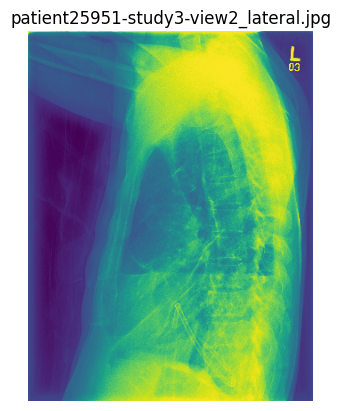

Image path: /content/chexpert-sample-data/sample/patient25951-study3-view2_lateral.jpg
    Lung Opacity: 1
    Pleural Effusion: 0
    Pneumothorax: 1



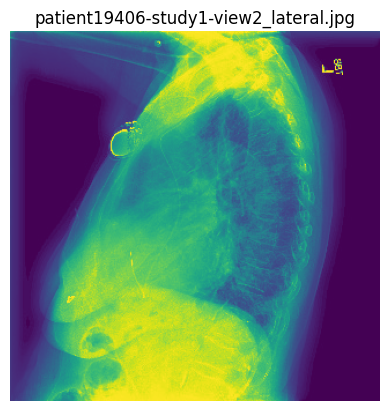

Image path: /content/chexpert-sample-data/sample/patient19406-study1-view2_lateral.jpg
    Lung Opacity: 1
    Pleural Effusion: 0
    Pneumothorax: 0



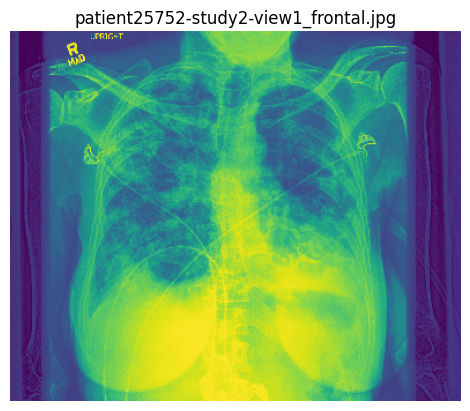

Image path: /content/chexpert-sample-data/sample/patient25752-study2-view1_frontal.jpg
    Lung Opacity: 1
    Pleural Effusion: 1
    Pneumothorax: 0



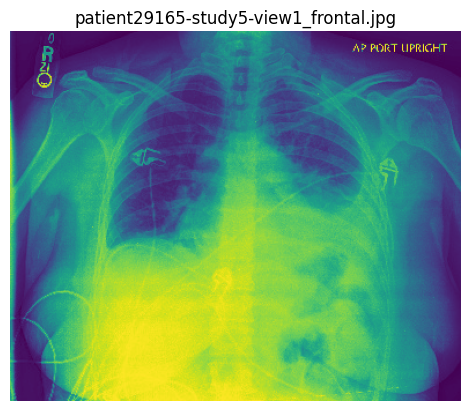

Image path: /content/chexpert-sample-data/sample/patient29165-study5-view1_frontal.jpg
    Lung Opacity: 1
    Pleural Effusion: 1
    Pneumothorax: 0



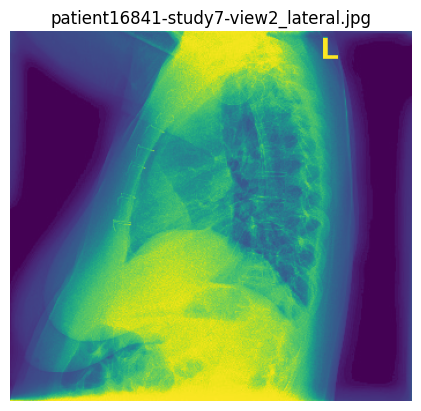

Image path: /content/chexpert-sample-data/sample/patient16841-study7-view2_lateral.jpg
    Lung Opacity: 1
    Pleural Effusion: 0
    Pneumothorax: 0



In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# Assuming 'sample5' DataFrame from the previous code is available
# and contains 'Path' and the triplet columns ('Lung Opacity', 'Pleural Effusion', 'Pneumothorax')

sample_base_dir = os.path.join(os.getcwd(), 'chexpert-sample-data', 'sample')  # Set base directory

for _, row in sample5.iterrows():
    # Extract parts from original path
    parts = row['Path'].split('/')[-3:]
    patient_id = parts[0].replace('patient', '')
    study_id = parts[1].replace('study', '')
    view = parts[2]

    # Construct new path
    image_path = os.path.join(sample_base_dir, f"patient{patient_id}-study{study_id}-{view}")

    try:
        img = mpimg.imread(image_path)
        plt.figure()
        plt.imshow(img)
        plt.title(os.path.basename(image_path))
        plt.axis('off')
        plt.show()

        print(f"Image path: {image_path}")
        for cls in triplet:
            print(f"    {cls}: {int(row[cls])}")
        print()
    except FileNotFoundError:
        print(f"Error: Image file not found at {image_path}")
    except Exception as e:
        print(f"Error displaying image {image_path}: {e}")

In [ ]:
# prompt: Just simply print this out in this order:
# patient25951-study3-view2_lateral.jpg:
# 1. This image includes Lung Opacity and Pneumothorax.
# 2. This image does not include Pleural Effusion.
# 3. This image includes Lung Opacity but not Pleural Effusion.
# patient19406-study1-view2_lateral.jpg:
# 1. This image includes Lung Opacity.
# 2. This image does not include Pleural Effusion or Pneumothorax.
# 3. This image includes Lung Opacity but not Pneumothorax.
# patient25752-study2-view1_frontal.jpg:
# 1. This image includes Lung Opacity and Pleural Effusion.
# 2. This image does not include Pneumothorax.
# 3. This image includes Pleural Effusion but not Pneumothorax.
# patient29165-study5-view1_frontal.jpg
# 1. This image includes Lung Opacity and Pleural Effusion.
# 2. This image does not include Pneumothorax.
# 3. This image includes Lung Opacity but not Pneumothorax.
# patient16841-study7-view2_lateral.jpg
# 1. This image includes Lung Opacity.
# 2. This image does not include Pleural Effusion or Pneumothorax.
# 3. This image includes Lung Opacity but not Pleural Effusion.

print("patient25951-study3-view2_lateral.jpg:")
print("1. This image includes Lung Opacity and Pneumothorax.")
print("2. This image does not include Pleural Effusion.")
print("3. This image includes Lung Opacity but not Pleural Effusion.")
print()
print("patient19406-study1-view2_lateral.jpg:")
print("1. This image includes Lung Opacity.")
print("2. This image does not include Pleural Effusion or Pneumothorax.")
print("3. This image includes Lung Opacity but not Pneumothorax.")
print()
print("patient25752-study2-view1_frontal.jpg:")
print("1. This image includes Lung Opacity and Pleural Effusion.")
print("2. This image does not include Pneumothorax.")
print("3. This image includes Pleural Effusion but not Pneumothorax.")
print()
print("patient29165-study5-view1_frontal.jpg")
print("1. This image includes Lung Opacity and Pleural Effusion.")
print("2. This image does not include Pneumothorax.")
print("3. This image includes Lung Opacity but not Pneumothorax.")
print()
print("patient16841-study7-view2_lateral.jpg")
print("1. This image includes Lung Opacity.")
print("2. This image does not include Pleural Effusion or Pneumothorax.")
print("3. This image includes Lung Opacity but not Pleural Effusion.")
print()

patient25951-study3-view2_lateral.jpg:
1. This image includes Lung Opacity and Pneumothorax.
2. This image does not include Pleural Effusion.
3. This image includes Lung Opacity but not Pleural Effusion.

patient19406-study1-view2_lateral.jpg:
1. This image includes Lung Opacity.
2. This image does not include Pleural Effusion or Pneumothorax.
3. This image includes Lung Opacity but not Pneumothorax.

patient25752-study2-view1_frontal.jpg:
1. This image includes Lung Opacity and Pleural Effusion.
2. This image does not include Pneumothorax.
3. This image includes Pleural Effusion but not Pneumothorax.

patient29165-study5-view1_frontal.jpg
1. This image includes Lung Opacity and Pleural Effusion.
2. This image does not include Pneumothorax.
3. This image includes Lung Opacity but not Pneumothorax.

patient16841-study7-view2_lateral.jpg
1. This image includes Lung Opacity.
2. This image does not include Pleural Effusion or Pneumothorax.
3. This image includes Lung Opacity but not Pleura

In [ ]:
# prompt: delete chexpert-sample-data/sample and chexpert-sample-data/sample.zip

!rm -rf chexpert-sample-data/sample chexpert-sample-data/sample.zip


In [ ]:
# prompt: unzip chexpert-sample-data/sample.zip

!unzip chexpert-sample-data/sample.zip


Archive:  chexpert-sample-data/sample.zip
   creating: sample/
  inflating: sample/patient16841-study7-view2_lateral.jpg  
  inflating: sample/patient19406-study1-view2_lateral.jpg  
  inflating: sample/patient25752-study2-view1_frontal.jpg  
  inflating: sample/patient25951-study3-view2_lateral.jpg  
  inflating: sample/patient29165-study5-view1_frontal.jpg  
